# 03 - Model Training & Evaluation
## TF-IDF Vectorization + Classification Models

**Objective:** Vectorize text, train models, compare results, and pick the best one.

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

## 1. Load Preprocessed Data

In [2]:
train_df = pd.read_csv('../artifacts/data_transformation/train.csv')
test_df = pd.read_csv('../artifacts/data_transformation/test.csv')

print(f'Train shape: {train_df.shape}')
print(f'Test shape:  {test_df.shape}')

X_train = train_df['content']
y_train = train_df['label']
X_test = test_df['content']
y_test = test_df['label']

# Handle any NaN in content
X_train = X_train.fillna('')
X_test = X_test.fillna('')

Train shape: (57664, 2)
Test shape:  (14416, 2)


## 2. TF-IDF Vectorization

In [3]:
tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f'TF-IDF train shape: {X_train_tfidf.shape}')
print(f'TF-IDF test shape:  {X_test_tfidf.shape}')

TF-IDF train shape: (57664, 5000)
TF-IDF test shape:  (14416, 5000)


## 3. Train Multiple Models

In [4]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
}

results = []

for name, model in models.items():
    print(f'Training {name}...')
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })
    
    print(f'  Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}')
    print()

Training Logistic Regression...
  Accuracy: 0.9491 | Precision: 0.9458 | Recall: 0.9557 | F1: 0.9507

Training Decision Tree...
  Accuracy: 0.9328 | Precision: 0.9250 | Recall: 0.9459 | F1: 0.9353

Training Random Forest...
  Accuracy: 0.9563 | Precision: 0.9476 | Recall: 0.9686 | F1: 0.9580

Training Gradient Boosting...
  Accuracy: 0.9417 | Precision: 0.9256 | Recall: 0.9641 | F1: 0.9445



## 4. Compare Results

In [5]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('F1-Score', ascending=False)
print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-Score
      Random Forest  0.956299   0.947584 0.968556  0.957955
Logistic Regression  0.949084   0.945780 0.955735  0.950732
  Gradient Boosting  0.941731   0.925628 0.964103  0.944474
      Decision Tree  0.932783   0.925036 0.945884  0.935344


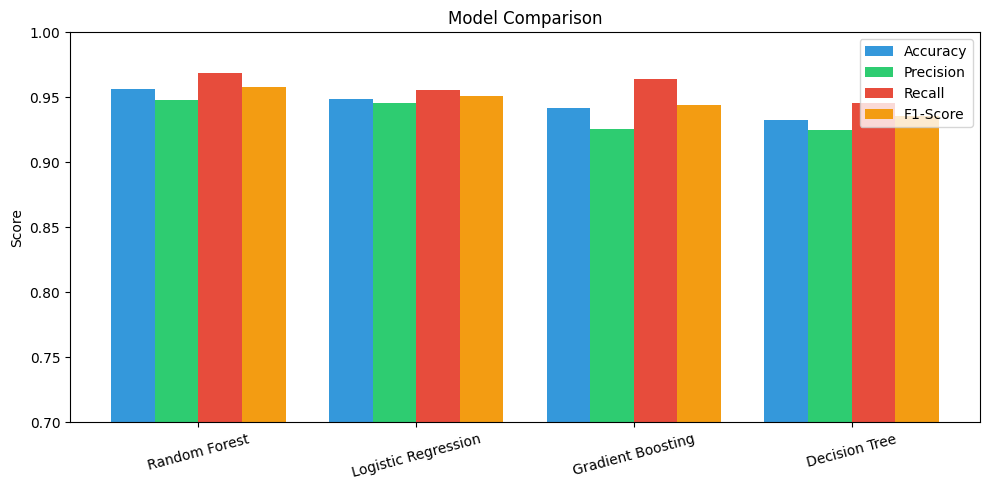

In [6]:
# Visualize comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(results_df))
width = 0.2

ax.bar(x - 1.5*width, results_df['Accuracy'], width, label='Accuracy', color='#3498db')
ax.bar(x - 0.5*width, results_df['Precision'], width, label='Precision', color='#2ecc71')
ax.bar(x + 0.5*width, results_df['Recall'], width, label='Recall', color='#e74c3c')
ax.bar(x + 1.5*width, results_df['F1-Score'], width, label='F1-Score', color='#f39c12')

ax.set_xticks(x)
ax.set_xticklabels(results_df['Model'], rotation=15)
ax.set_ylabel('Score')
ax.set_title('Model Comparison')
ax.legend()
ax.set_ylim(0.7, 1.0)
plt.tight_layout()
plt.show()

## 5. Best Model - Detailed Report

In [7]:
# Pick the best model based on F1 score
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
print(f'Best model: {best_model_name}')

y_pred_best = best_model.predict(X_test_tfidf)

print('\nClassification Report:')
print(classification_report(y_test, y_pred_best, target_names=['Fake', 'Real']))

Best model: Random Forest

Classification Report:
              precision    recall  f1-score   support

        Fake       0.97      0.94      0.95      7006
        Real       0.95      0.97      0.96      7410

    accuracy                           0.96     14416
   macro avg       0.96      0.96      0.96     14416
weighted avg       0.96      0.96      0.96     14416



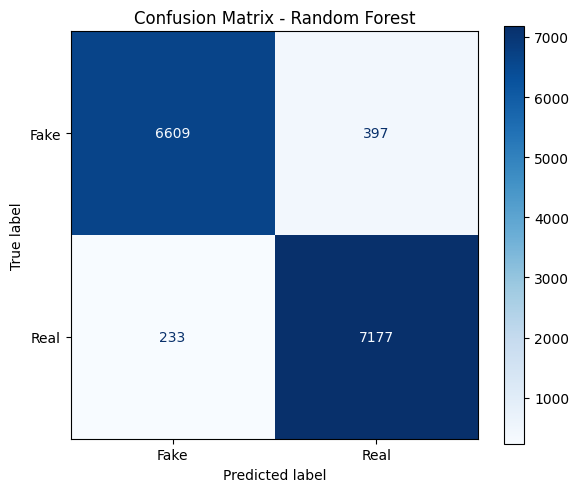

In [8]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(cmap='Blues', ax=ax)
ax.set_title(f'Confusion Matrix - {best_model_name}')
plt.tight_layout()
plt.show()

## 6. Save Best Model & Vectorizer

In [9]:
import os
os.makedirs('../artifacts/model_trainer', exist_ok=True)

# Save model
joblib.dump(best_model, '../artifacts/model_trainer/model.joblib')
print(f'Model saved: artifacts/model_trainer/model.joblib')

# Save TF-IDF vectorizer
joblib.dump(tfidf, '../artifacts/model_trainer/tfidf_vectorizer.joblib')
print(f'Vectorizer saved: artifacts/model_trainer/tfidf_vectorizer.joblib')

Model saved: artifacts/model_trainer/model.joblib
Vectorizer saved: artifacts/model_trainer/tfidf_vectorizer.joblib


## 7. Quick Prediction Test

In [10]:
# Load and test
loaded_model = joblib.load('../artifacts/model_trainer/model.joblib')
loaded_tfidf = joblib.load('../artifacts/model_trainer/tfidf_vectorizer.joblib')

test_texts = [
    "Breaking: Scientists discover new cure for cancer approved by FDA",
    "SHOCKING: Government secretly controls weather using chemtrails",
]

test_vectorized = loaded_tfidf.transform(test_texts)
predictions = loaded_model.predict(test_vectorized)

for text, pred in zip(test_texts, predictions):
    label = 'REAL' if pred == 1 else 'FAKE'
    print(f'[{label}] {text}')

[REAL] Breaking: Scientists discover new cure for cancer approved by FDA
[REAL] SHOCKING: Government secretly controls weather using chemtrails


## 8. Summary

Record your findings:
- Which model performed best?
- What was the F1-Score?
- Any observations on the confusion matrix?
- Next steps for the modular pipeline